<a href="https://colab.research.google.com/github/anitabudhiraja/DeepLearning/blob/main/mnist_cnn_17_Nov_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST Handwritten Digit Recognition using a Convolutional Neural Network (CNN)

**Prepared for:** NIELIT Chandigarh / Ropar  |  **Prerequisite:** the *ANN on MNIST* notebook

---

## Learning Objectives
By the end of this session, students will be able to:

1. Explain **why** a plain ANN is not ideal for images and **how** a CNN fixes this.
2. Describe the roles of **convolution, ReLU, pooling, flatten, dense and dropout** layers.
3. **Calculate** output shapes and number of parameters of a CNN by hand and verify with `model.summary()`.
4. Build, train and evaluate **two CNN models** in Keras (a simple one and an improved one).
5. Detect **overfitting** from training curves and reduce it using **Dropout** and **EarlyStopping**.
6. **Visualise what a CNN "sees"** – learned filters and feature maps.
7. Save/load a model and **predict on your own handwritten digit**.

## Roadmap

| Part | Topic |
|------|-------|
| 1 | Setup & imports |
| 2 | Load and explore data |
| 3 | Pre-processing (reshape, normalise, split) |
| 4 | Concept lab: convolution & pooling by hand |
| 5 | Model 1 – Simple CNN |
| 6 | Model 2 – Improved CNN (Conv + Pool + Dropout) |
| 7 | ANN vs CNN comparison |
| 8 | Detailed evaluation – confusion matrix & mistakes |
| 9 | Looking inside the CNN – filters & feature maps |
| 10 | Save, load and predict |
| 11 | Predict your own handwritten digit |
| 12 | Summary, exercises & viva questions |

>  **Tip:** Use a GPU for faster training: *Runtime → Change runtime type → T4 GPU*. The notebook also runs fine on CPU (a few minutes).

---
# Part 1: Setup & Imports

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version :", tf.__version__)
print("Keras version      :", keras.__version__)
print("GPU available      :", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version : 2.21.0
Keras version      : 3.13.2
GPU available      : False


### Make results reproducible
Neural networks start with **random weights**. Setting a *seed* makes the experiment repeat the same way (results may still differ slightly on GPU).

In [2]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("Random seed set to", SEED)

Random seed set to 42


---
# Part 2: Load and Explore the MNIST Dataset

MNIST has **70,000** grayscale images of handwritten digits (0–9), each **28 × 28** pixels:
* 60,000 for training
* 10,000 for testing

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train shape:", x_train.shape, "| dtype:", x_train.dtype)
print("y_train shape:", y_train.shape)
print("x_test  shape:", x_test.shape)
print("y_test  shape:", y_test.shape)
print("Pixel range  : min =", x_train.min(), " max =", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28) | dtype: uint8
y_train shape: (60000,)
x_test  shape: (10000, 28, 28)
y_test  shape: (10000,)
Pixel range  : min = 0  max = 255


### 2.1 Look at some images

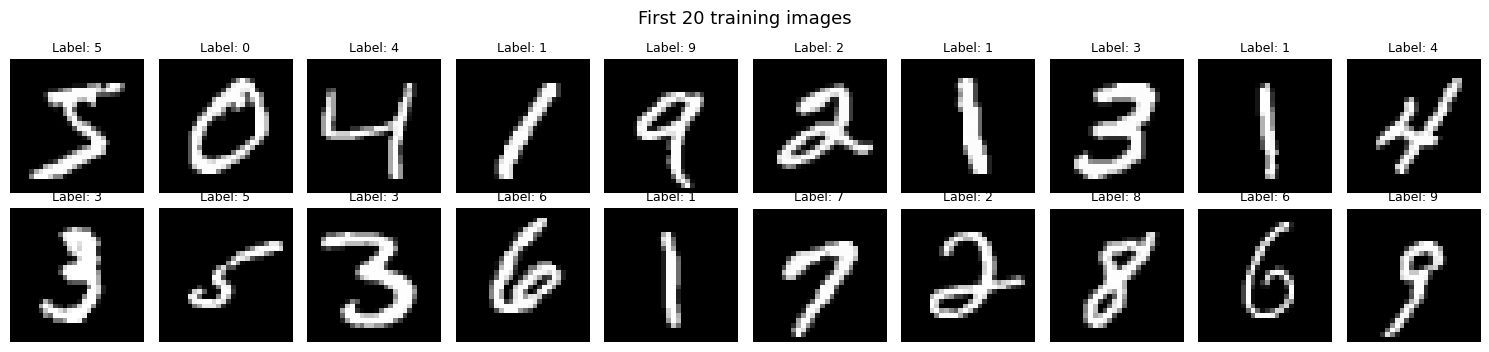

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f"Label: {y_train[i]}", fontsize=9)
    ax.axis('off')
plt.suptitle("First 20 training images", fontsize=13)
plt.tight_layout()
plt.show()

### 2.2 Is the dataset balanced?
A good classifier needs roughly equal examples of every class.

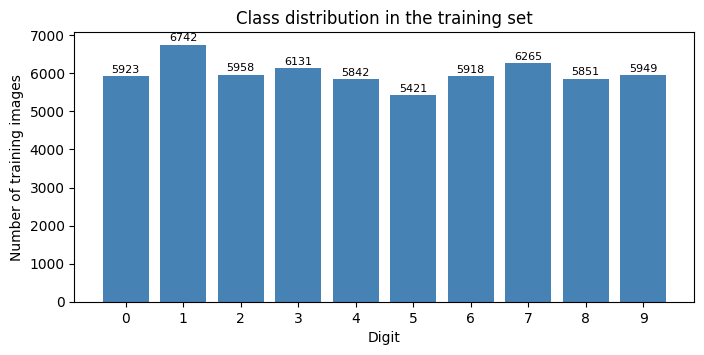

In [5]:
digits, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(8, 3.5))
bars = plt.bar(digits, counts, color='steelblue')
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Number of training images")
plt.title("Class distribution in the training set")
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width()/2, c + 100, str(c), ha='center', fontsize=8)
plt.show()

### 2.3 What does the computer actually see?
To a computer an image is just a **grid of numbers** (0 = black, 255 = white).

Label of this image: 5


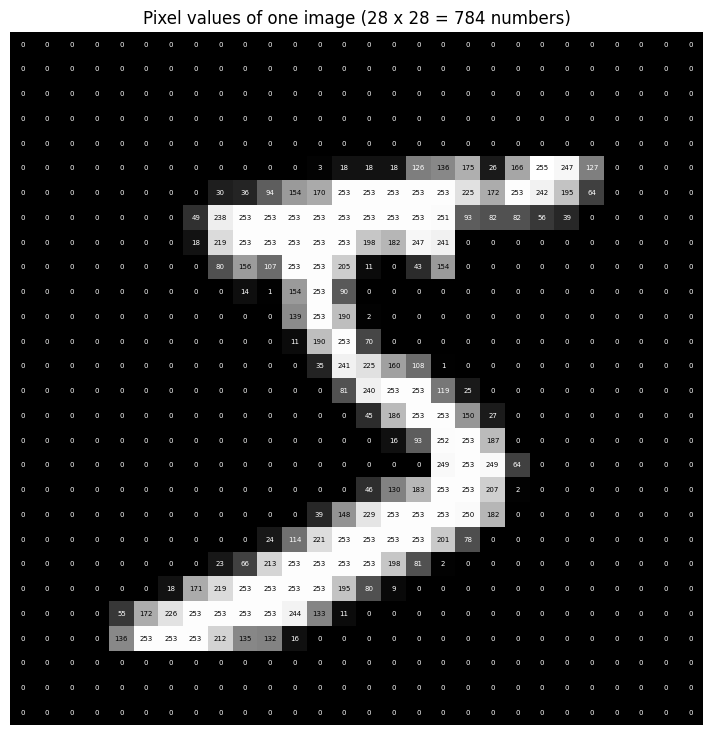

In [6]:
sample = x_train[0]
print("Label of this image:", y_train[0])

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(sample, cmap='gray')
for r in range(28):
    for c in range(28):
        v = sample[r, c]
        ax.text(c, r, str(v), ha='center', va='center', fontsize=5,
                color='white' if v < 128 else 'black')
ax.axis('off')
plt.title("Pixel values of one image (28 x 28 = 784 numbers)")
plt.show()

---
# Part 3: Pre-processing

Three things must be done before feeding images to a CNN:

| Step | Why |
|------|-----|
| **Normalise** pixels to [0, 1] | Helps the optimiser converge faster and more stably |
| **Add a channel dimension** → `(28, 28, 1)` | A CNN expects `(height, width, channels)`. Grayscale = 1 channel (RGB would be 3) |
| **Split** off a validation set | To monitor overfitting *during* training without touching the test set |

### 🔑 ANN vs CNN input
* **ANN** flattened the image into **784 numbers** → *spatial structure is lost*.
* **CNN** keeps the image as a **2-D grid** → neighbouring pixels stay neighbours.

In [7]:
# 1. Normalise to [0, 1] and convert to float32
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# 2. Add the channel dimension: (N, 28, 28) -> (N, 28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

print("x_train shape:", x_train.shape)
print("x_test  shape:", x_test.shape)
print(f"Pixel range now: min={x_train.min()}, max={x_train.max()}")

x_train shape: (60000, 28, 28, 1)
x_test  shape: (10000, 28, 28, 1)
Pixel range now: min=0.0, max=1.0


### Labels
We keep labels as **integers (0–9)** and use `sparse_categorical_crossentropy` – exactly as in the ANN notebook.

> 📝 *Alternative:* convert labels to one-hot vectors with `keras.utils.to_categorical` and use `categorical_crossentropy`. Both give the same result.

### Train / validation split
We hold out **10 %** of the training data for validation. `stratify` keeps the class proportions equal in both parts.

In [8]:
from sklearn.model_selection import train_test_split

x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train
)

print("Training   :", x_tr.shape,  y_tr.shape)
print("Validation :", x_val.shape, y_val.shape)
print("Test       :", x_test.shape, y_test.shape)

Training   : (54000, 28, 28, 1) (54000,)
Validation : (6000, 28, 28, 1) (6000,)
Test       : (10000, 28, 28, 1) (10000,)


---
# Part 4: Concept Lab – Convolution and Pooling "by hand"

Before using Keras, let us **see** what the two key CNN operations do.

## 4.1 Convolution
A **filter (kernel)** is a small matrix (e.g. 3 × 3). It slides over the image; at every position we
**multiply element-wise and add** the results → one number in the output **feature map**.

$$\text{output}(i,j) = \sum_{m=0}^{2}\sum_{n=0}^{2} \text{image}(i+m,\; j+n)\times \text{kernel}(m,n)$$

Different filters detect different patterns. Below we apply **hand-made** filters. In a CNN, the network **learns** the filter values by itself!

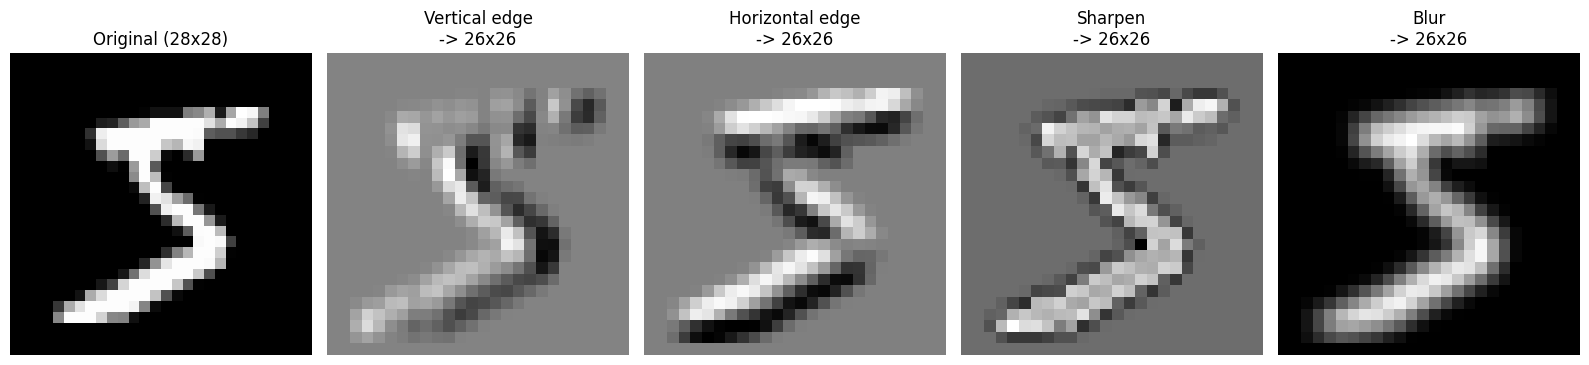

In [9]:
def convolve2d(image, kernel):
    # Simple 'valid' convolution (no padding, stride 1) written with loops for clarity.
    kh, kw = kernel.shape
    ih, iw = image.shape
    out = np.zeros((ih - kh + 1, iw - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            region = image[i:i+kh, j:j+kw]
            out[i, j] = np.sum(region * kernel)
    return out

# A few classic hand-crafted 3x3 filters
filters = {
    "Vertical edge":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Sharpen":         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Blur":            np.ones((3, 3)) / 9.0,
}

img = x_train[0, :, :, 0]      # one digit, shape (28, 28)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(img, cmap='gray'); axes[0].set_title("Original (28x28)")
for ax, (name, k) in zip(axes[1:], filters.items()):
    fm = convolve2d(img, k)
    ax.imshow(fm, cmap='gray')
    ax.set_title(f"{name}\n-> {fm.shape[0]}x{fm.shape[1]}")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### 📐 Output size formula
For input size $n$, filter size $f$, padding $p$ and stride $s$:

$$\text{output size} = \left\lfloor \frac{n + 2p - f}{s} \right\rfloor + 1$$

Here: $n=28,\ f=3,\ p=0,\ s=1 \Rightarrow 28-3+1 = \mathbf{26}$. So a 28×28 image becomes a **26×26** feature map (`padding='valid'`).  
With `padding='same'` zeros are added around the image so the size stays 28×28.

## 4.2 ReLU activation
ReLU keeps positive values and sets negatives to zero: $\text{ReLU}(x)=\max(0,x)$. It adds **non-linearity**, so the network can learn complex patterns.

## 4.3 Max Pooling
Pooling **shrinks** the feature map. A 2 × 2 max-pool slides a window and keeps only the **largest** value in each window.

**Benefits:** fewer parameters, faster training, a little tolerance to small shifts of the digit, less overfitting.

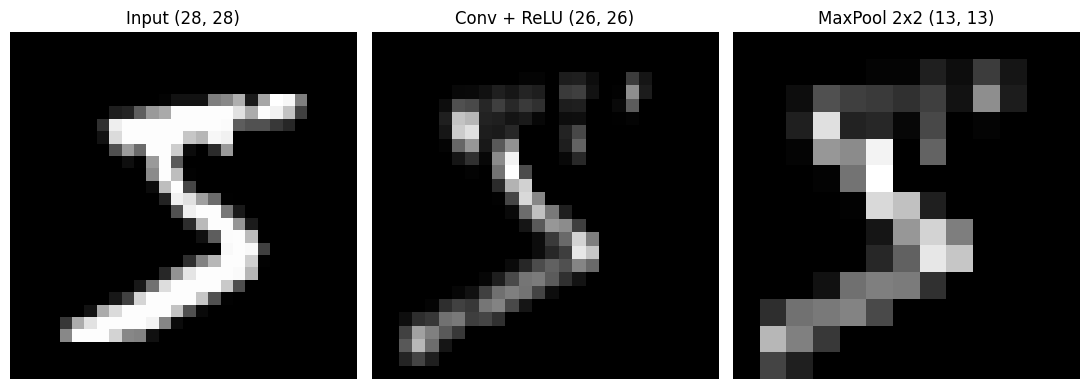

Tiny pooling example:
[[1 3 2 4]
 [5 6 1 2]
 [7 2 9 0]
 [1 8 3 4]] 
  ->  after 2x2 max-pool  ->
 [[6. 4.]
 [8. 9.]]


In [10]:
def max_pool2d(fm, size=2):
    h, w = fm.shape
    out = np.zeros((h // size, w // size))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = fm[i*size:(i+1)*size, j*size:(j+1)*size].max()
    return out

fm  = convolve2d(img, filters["Vertical edge"])
fm  = np.maximum(0, fm)            # ReLU
pooled = max_pool2d(fm, 2)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(img, cmap='gray');    axes[0].set_title(f"Input {img.shape}")
axes[1].imshow(fm, cmap='gray');     axes[1].set_title(f"Conv + ReLU {fm.shape}")
axes[2].imshow(pooled, cmap='gray'); axes[2].set_title(f"MaxPool 2x2 {pooled.shape}")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print("Tiny pooling example:")
demo = np.array([[1, 3, 2, 4],
                 [5, 6, 1, 2],
                 [7, 2, 9, 0],
                 [1, 8, 3, 4]])
print(demo, "\n  ->  after 2x2 max-pool  ->\n", max_pool2d(demo, 2))

## 4.4 Typical CNN pipeline

```
Image → [Conv → ReLU → Pool] → [Conv → ReLU → Pool] → Flatten → Dense → Softmax → Digit
        └──── feature extraction ────┘                   └──── classification ────┘
```

* **Convolution layers** automatically *learn features* (edges → curves → digit parts).
* **Dense layers** use these features to *classify*.
* **Softmax** converts 10 outputs into probabilities that sum to 1.

### ✍️ Quick think-and-answer (for class discussion)
1. If the input is 28×28 and we use a 5×5 filter with `valid` padding, what is the output size? *(Answer: 24×24)*
2. What is the size after a 2×2 max-pool on 24×24? *(Answer: 12×12)*

---
# Part 5: Model 1 – Simple CNN

Architecture: **one** convolution layer, then a dense output layer.

| Layer | Details |
|-------|---------|
| `Input` | 28 × 28 × 1 |
| `Conv2D` | 32 filters, 3×3, ReLU |
| `Flatten` | converts 3-D feature maps to a 1-D vector |
| `Dense` | 10 neurons, Softmax |

### 🧮 Let us predict the parameters *before* running `summary()`

**Conv2D:** each filter has 3×3×1 = 9 weights + 1 bias = 10 → 32 filters × 10 = **320**  
**Output shape:** 26 × 26 × 32 = **21,632** values  
**Dense:** 21,632 × 10 weights + 10 biases = **216,330**  
**Total = 320 + 216,330 = 216,650**

In [11]:
cnn_simple = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), padding='valid', activation='relu'),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')
], name="Simple_CNN")

cnn_simple.summary()

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │       216,330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,650 (846.29 KB)

 Trainable params: 216,650 (846.29 KB)

 Non-trainable params: 0 (0.00 B)

Compare the summary with our hand calculation. Notice that **almost all parameters are in the Dense layer** – flattening a big feature map creates a huge connection.

### Compile
* **Optimizer – Adam:** adaptive learning rate; a reliable default.
* **Loss – sparse categorical cross-entropy:** for integer class labels with softmax output.
* **Metric – accuracy.**

In [12]:
cnn_simple.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Train
* **epoch** – one full pass over all training images
* **batch_size** – images processed before one weight update

In [13]:
print("Training Simple CNN...\n")
hist_simple = cnn_simple.fit(
    x_tr, y_tr,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1
)
print("\nTraining complete!")

Training Simple CNN...

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9381 - loss: 0.2192 - val_accuracy: 0.9727 - val_loss: 0.1073
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.9779 - loss: 0.0769 - val_accuracy: 0.9780 - val_loss: 0.0879
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 20ms/step - accuracy: 0.9842 - loss: 0.0544 - val_accuracy: 0.9797 - val_loss: 0.0821
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.9880 - loss: 0.0415 - val_accuracy: 0.9798 - val_loss: 0.0802
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9911 - loss: 0.0322 - val_accuracy: 0.9783 - val_loss: 0.0833
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9934 - loss: 0.0250 - val_accuracy: 0.9798 - val_loss: 0.0846
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9954 - loss: 0.0193 - val_accuracy: 0.9805 - val_loss: 0.0839
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 

😀

### Plot learning curves
A helper function that we will reuse. **Always check these curves!**

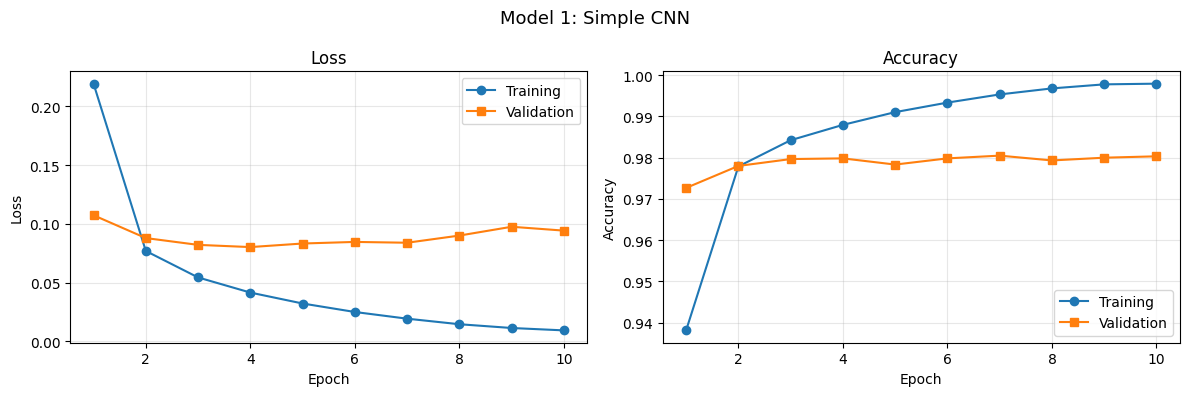

In [14]:
def plot_history(history, title=""):
    h = history.history
    epochs = range(1, len(h['loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h['loss'], 'o-', label='Training')
    axes[0].plot(epochs, h['val_loss'], 's-', label='Validation')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, h['accuracy'], 'o-', label='Training')
    axes[1].plot(epochs, h['val_accuracy'], 's-', label='Validation')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy'); axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)

    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_history(hist_simple, "Model 1: Simple CNN")

### How to read the curves (overfitting check)

| Pattern | Meaning |
|---------|---------|
| Both curves improve together | Good learning |
| Training loss ↓ but validation loss flat or ↑ | **Overfitting** – the model memorises the training data |
| Both curves poor | **Underfitting** – model too simple or too little training |

Look at the gap between training and validation. Is the model beginning to overfit?

### Evaluate on the unseen test set

In [15]:
test_loss_1, test_acc_1 = cnn_simple.evaluate(x_test, y_test, verbose=0)
print(f"Simple CNN  ->  Test Loss: {test_loss_1:.4f} | Test Accuracy: {test_acc_1*100:.2f}%")

Simple CNN  ->  Test Loss: 0.0896 | Test Accuracy: 97.94%


---
# Part 6: Model 2 – Improved CNN (Conv + Pooling + Dropout)

Real CNNs stack **several** Conv → Pool blocks. Early layers learn simple edges; deeper layers combine them into complex shapes.

| Layer | Output shape | Parameters |
|-------|--------------|-----------|
| Conv2D(32, 3×3) | 26×26×32 | 320 |
| MaxPooling2D(2×2) | 13×13×32 | 0 |
| Conv2D(64, 3×3) | 11×11×64 | 18,496 |
| MaxPooling2D(2×2) | 5×5×64 | 0 |
| Flatten | 1600 | 0 |
| Dropout(0.5) | 1600 | 0 |
| Dense(10, softmax) | 10 | 16,010 |
| **Total** | | **34,826** |

(Conv2 parameters: 3×3×**32** inputs + 1 bias = 289 per filter × 64 = 18,496. Pooling and Dropout have **no** parameters.)

### What is Dropout?
During training, Dropout randomly switches off a fraction of neurons (here 50 %) in each step. The network cannot rely on any single neuron, so it generalises better. **Dropout is active only during training**, not during testing.

In [16]:
cnn_improved = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', name='conv1'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', name='conv2'),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
], name="Improved_CNN")

cnn_improved.summary()

Model: "Improved_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

🧐 **Observe:** this model has **far fewer** parameters (≈ 35 K) than Model 1 (≈ 217 K) – yet it should be **more accurate**. Pooling and stacked convolutions are efficient!

### Callbacks
* **EarlyStopping** – stops training when validation loss stops improving and restores the best weights.
* **ModelCheckpoint** – saves the best model to disk.

In [17]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint('best_mnist_cnn.keras', monitor='val_loss',
                                    save_best_only=True, verbose=0)
]

cnn_improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training Improved CNN...\n")
hist_improved = cnn_improved.fit(
    x_tr, y_tr,
    epochs=20,                 # upper limit; EarlyStopping may stop sooner
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks,
    verbose=1
)
print("\nTraining complete!")

Training Improved CNN...

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 58ms/step - accuracy: 0.9162 - loss: 0.2732 - val_accuracy: 0.9737 - val_loss: 0.0911
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9711 - loss: 0.0937 - val_accuracy: 0.9837 - val_loss: 0.0646
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 47ms/step - accuracy: 0.9782 - loss: 0.0696 - val_accuracy: 0.9848 - val_loss: 0.0588
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 45ms/step - accuracy: 0.9819 - loss: 0.0578 - val_accuracy: 0.9868 - val_loss: 0.0508
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 45ms/step - accuracy: 0.9837 - loss: 0.0529 - val_accuracy: 0.9875 - val_loss: 0.0511
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9851 - loss: 0.0480 - val_accuracy: 0.9893 - val_loss: 0.0429
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9862 - loss: 0.0442 - val_accuracy: 0.9897 - val_loss: 0.0411
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy

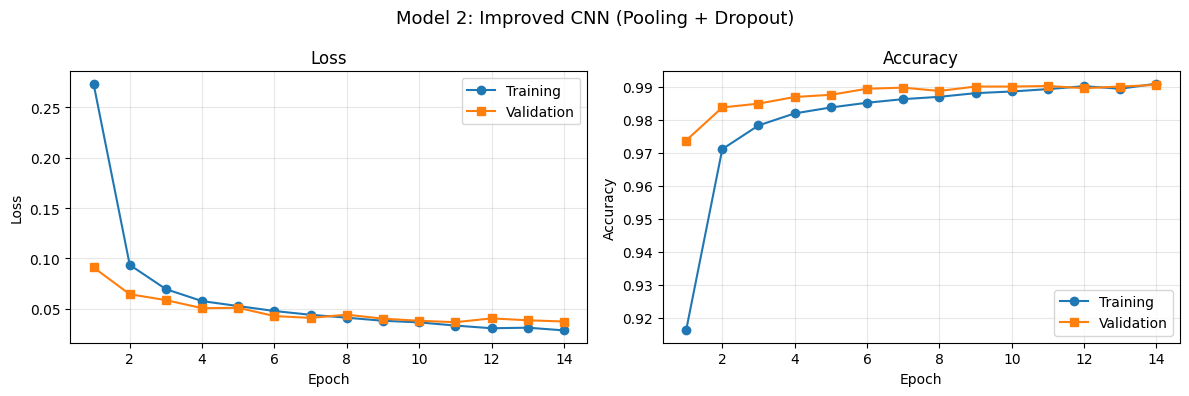

In [18]:
plot_history(hist_improved, "Model 2: Improved CNN (Pooling + Dropout)")

> 🔎 **Discussion:** With Dropout, the *training* accuracy can look slightly **lower** than validation accuracy in early epochs. That is normal – Dropout is on during training but off during validation.

In [19]:
test_loss_2, test_acc_2 = cnn_improved.evaluate(x_test, y_test, verbose=0)
print(f"Improved CNN ->  Test Loss: {test_loss_2:.4f} | Test Accuracy: {test_acc_2*100:.2f}%")

Improved CNN ->  Test Loss: 0.0233 | Test Accuracy: 99.24%


---
# Part 7: ANN vs CNN – A Fair Comparison

We rebuild the **ANN from the previous session** (784 → 128 → 64 → 10), train it on the *same* split, and compare.

https://colab.research.google.com/github/anitabudhiraja/DeepLearning/blob/main/ANN_MNIST.ipynb

In [20]:
ann = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
], name="ANN_baseline")

ann.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# ANN needs flattened input
x_tr_flat   = x_tr.reshape(len(x_tr), 784)
x_val_flat  = x_val.reshape(len(x_val), 784)
x_test_flat = x_test.reshape(len(x_test), 784)

hist_ann = ann.fit(x_tr_flat, y_tr, epochs=10, batch_size=64,
                   validation_data=(x_val_flat, y_val), verbose=0)

test_loss_ann, test_acc_ann = ann.evaluate(x_test_flat, y_test, verbose=0)
print(f"ANN done. Test accuracy = {test_acc_ann*100:.2f}%")

ANN done. Test accuracy = 97.72%


In [21]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["ANN (Dense only)", "Model 1: Simple CNN", "Model 2: Improved CNN"],
    "Parameters": [ann.count_params(), cnn_simple.count_params(), cnn_improved.count_params()],
    "Test Accuracy (%)": [test_acc_ann*100, test_acc_1*100, test_acc_2*100],
    "Test Errors (out of 10,000)": [int(round((1-test_acc_ann)*10000)),
                                    int(round((1-test_acc_1)*10000)),
                                    int(round((1-test_acc_2)*10000))],
})
results["Test Accuracy (%)"] = results["Test Accuracy (%)"].round(2)
results

,Model,Parameters,Test Accuracy (%),"Test Errors (out of 10,000)"
0,ANN (Dense only),109386,97.72,228
1,Model 1: Simple CNN,216650,97.94,206
2,Model 2: Improved CNN,34826,99.24,76


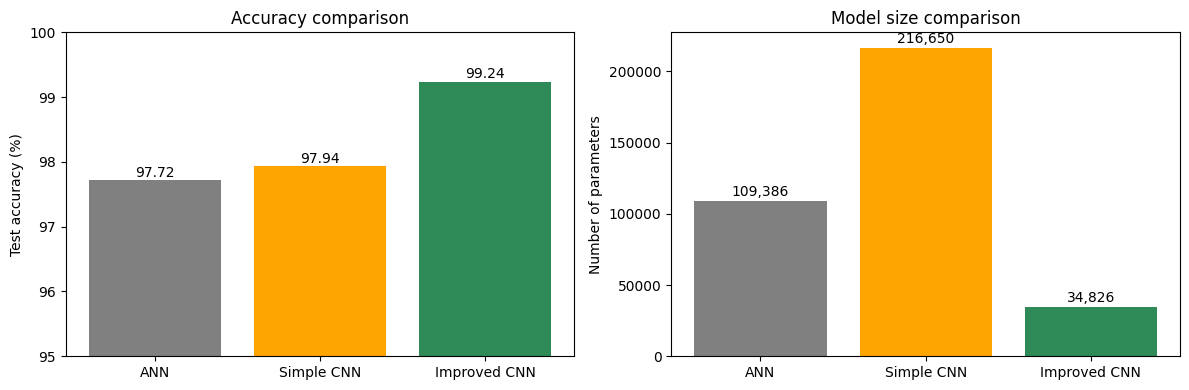

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

names = ["ANN", "Simple CNN", "Improved CNN"]
axes[0].bar(names, results["Test Accuracy (%)"], color=['gray', 'orange', 'seagreen'])
axes[0].set_ylim(95, 100)
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("Accuracy comparison")
for i, v in enumerate(results["Test Accuracy (%)"]):
    axes[0].text(i, v + 0.05, f"{v:.2f}", ha='center')

axes[1].bar(names, results["Parameters"], color=['gray', 'orange', 'seagreen'])
axes[1].set_ylabel("Number of parameters")
axes[1].set_title("Model size comparison")
for i, v in enumerate(results["Parameters"]):
    axes[1].text(i, v + 3000, f"{v:,}", ha='center')

plt.tight_layout(); plt.show()

### 💬 Key takeaways
* The CNN achieves **higher accuracy with fewer parameters** than the ANN.
* **Weight sharing:** the *same* 3×3 filter is reused across the whole image, so far fewer weights are needed.
* **Local connectivity:** each neuron looks only at a small patch, which suits images.
* The gap looks small on MNIST (an easy dataset); on **real-world images (faces, objects, medical scans)** the advantage of CNNs is **dramatic**.

---
# Part 8: Detailed Evaluation of the Best Model

## 8.1 Confusion matrix

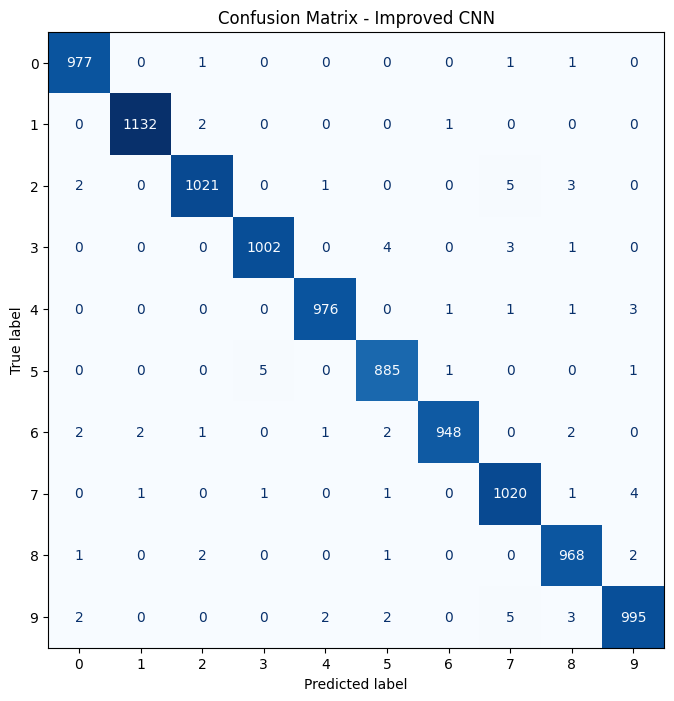

In [23]:
y_pred_probs = cnn_improved.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
plt.title("Confusion Matrix - Improved CNN")
plt.show()

* **Diagonal** = correct predictions. **Off-diagonal** = mistakes.
* Which pair of digits is confused most often? (Often 4↔9, 3↔5, 7↔2.)

In [24]:
# Find the most confused pairs automatically
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]

print("Top-5 confusions (True -> Predicted : count)")
for t, p in top:
    print(f"   {t} -> {p} : {cm_off[t, p]}")

Top-5 confusions (True -> Predicted : count)
   9 -> 7 : 5
   5 -> 3 : 5
   2 -> 7 : 5
   7 -> 9 : 4
   3 -> 5 : 4


## 8.2 Precision, Recall and F1-score per digit

In [25]:
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9929    0.9969    0.9949       980
           1     0.9974    0.9974    0.9974      1135
           2     0.9942    0.9893    0.9917      1032
           3     0.9940    0.9921    0.9931      1010
           4     0.9959    0.9939    0.9949       982
           5     0.9888    0.9922    0.9905       892
           6     0.9968    0.9896    0.9932       958
           7     0.9855    0.9922    0.9889      1028
           8     0.9878    0.9938    0.9908       974
           9     0.9900    0.9861    0.9881      1009

    accuracy                         0.9924     10000
   macro avg     0.9923    0.9924    0.9923     10000
weighted avg     0.9924    0.9924    0.9924     10000



| Metric | Meaning |
|--------|---------|
| **Precision** | Of all images predicted as digit *d*, how many really are *d*? |
| **Recall** | Of all real images of digit *d*, how many did we find? |
| **F1-score** | Harmonic mean of precision and recall |

## 8.3 Let us look at the mistakes
Studying errors tells us *why* the model fails – often even humans find these digits ambiguous.

Total misclassified images: 76 out of 10000


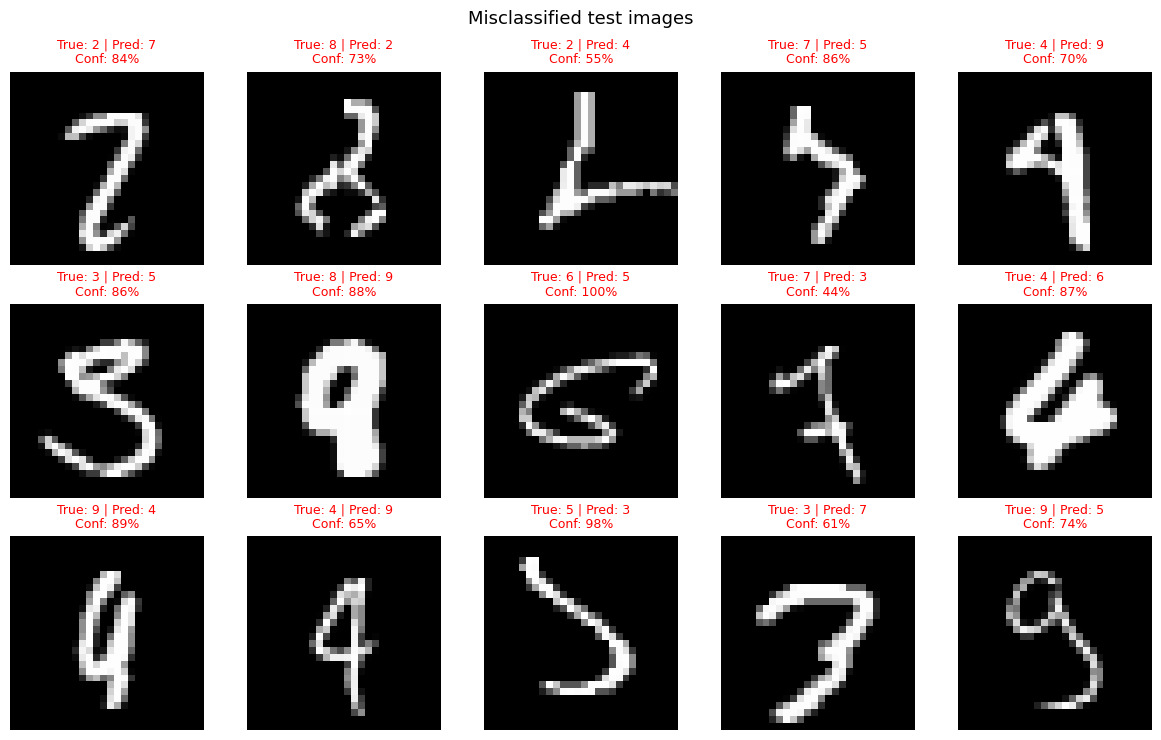

In [26]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Total misclassified images: {len(wrong_idx)} out of {len(y_test)}")

n_show = min(15, len(wrong_idx))
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for ax, idx in zip(axes.flat, wrong_idx[:n_show]):
    ax.imshow(x_test[idx, :, :, 0], cmap='gray')
    conf = y_pred_probs[idx, y_pred[idx]] * 100
    ax.set_title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}\nConf: {conf:.0f}%", color='red', fontsize=9)
    ax.axis('off')
plt.suptitle("Misclassified test images", fontsize=13)
plt.tight_layout(); plt.show()

---
# Part 9: Looking Inside the CNN – What Did It Learn?

Neural networks are often called "black boxes". For CNNs we can **open the box**.

## 9.1 Learned filters (first convolution layer)
Remember our hand-made edge filters? The network learned its **own** 32 filters.

conv1 weight shape: (3, 3, 1, 32)  -> (height, width, in_channels, n_filters)


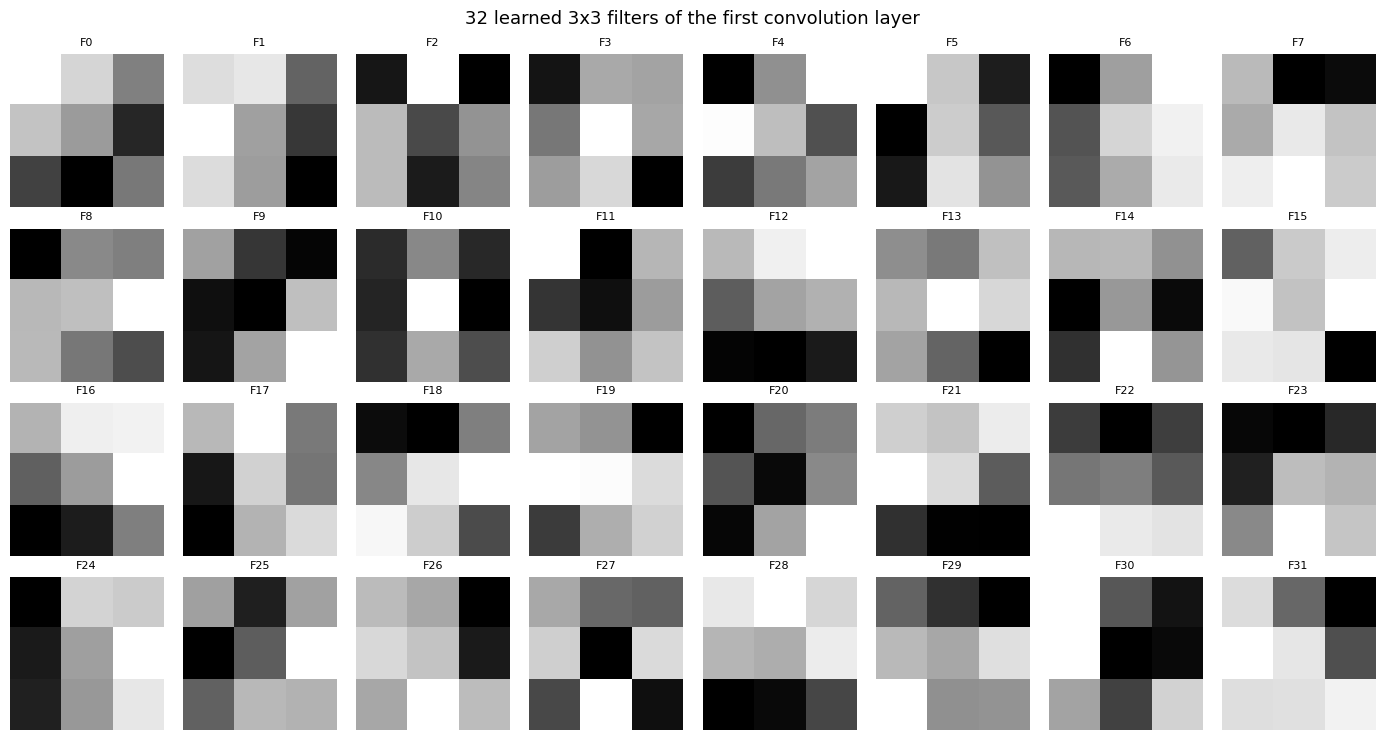

In [27]:
filters_w, biases_b = cnn_improved.get_layer('conv1').get_weights()
print("conv1 weight shape:", filters_w.shape, " -> (height, width, in_channels, n_filters)")

fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(filters_w[:, :, 0, i], cmap='gray')
    ax.set_title(f"F{i}", fontsize=8)
    ax.axis('off')
plt.suptitle("32 learned 3x3 filters of the first convolution layer", fontsize=13)
plt.tight_layout(); plt.show()

## 9.2 Feature maps (activations)
We feed **one image** and look at what each convolution layer outputs.

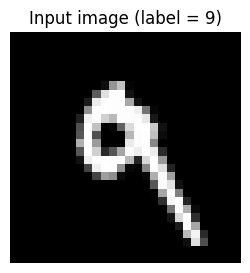

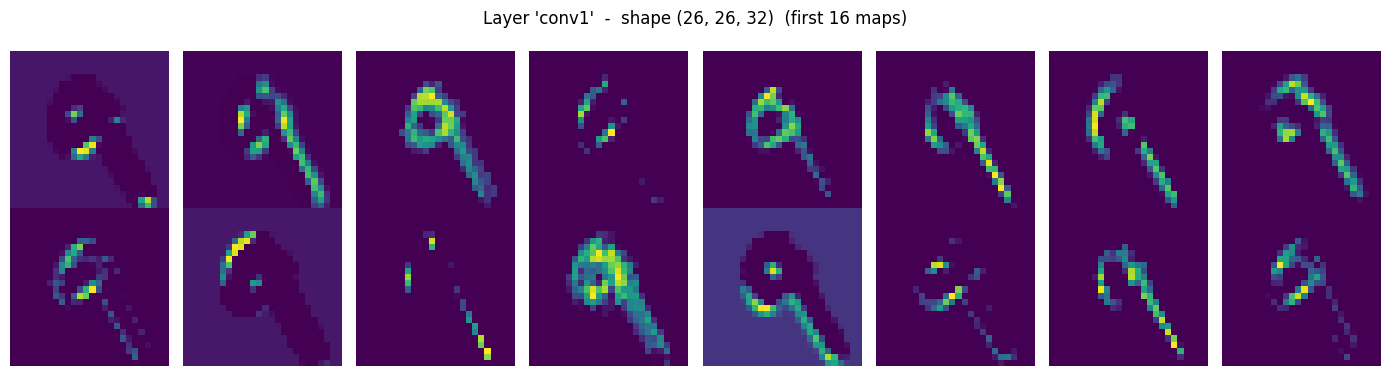

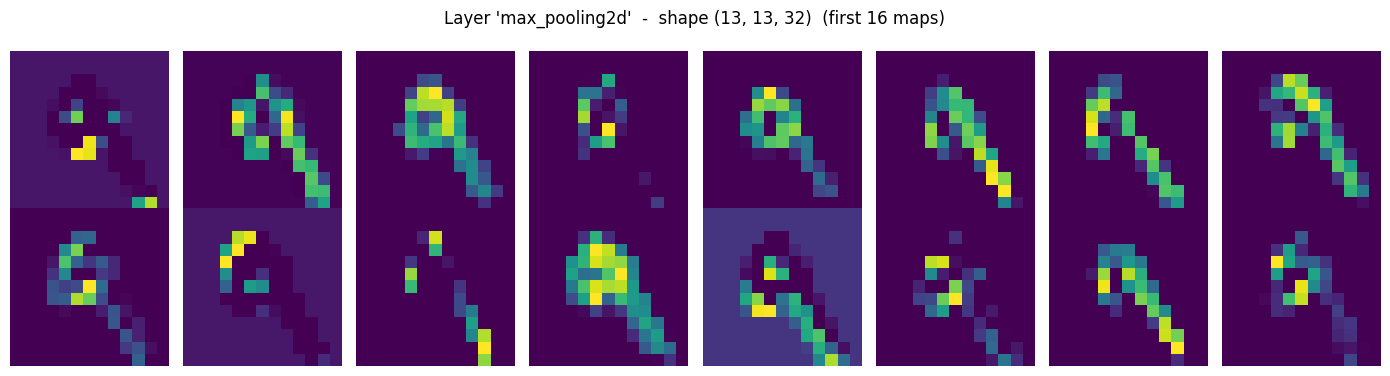

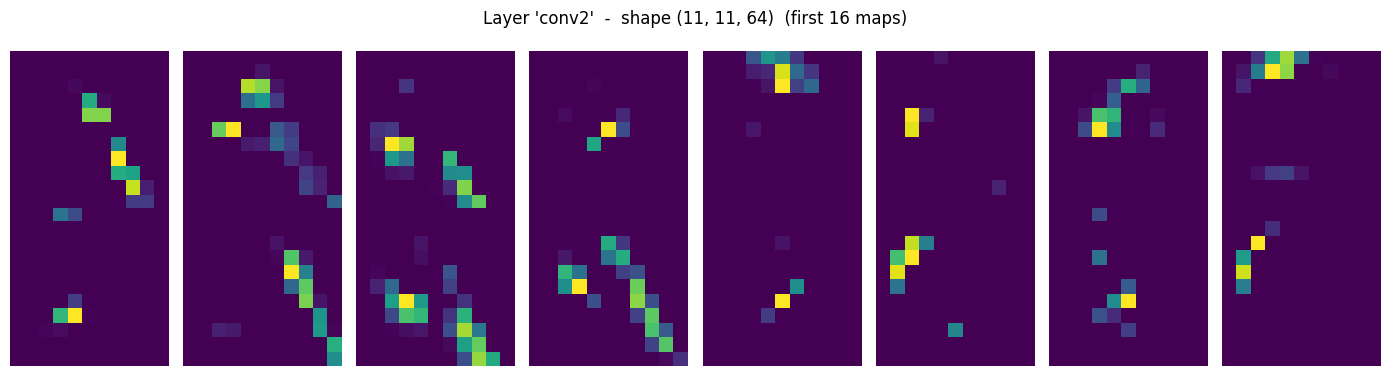

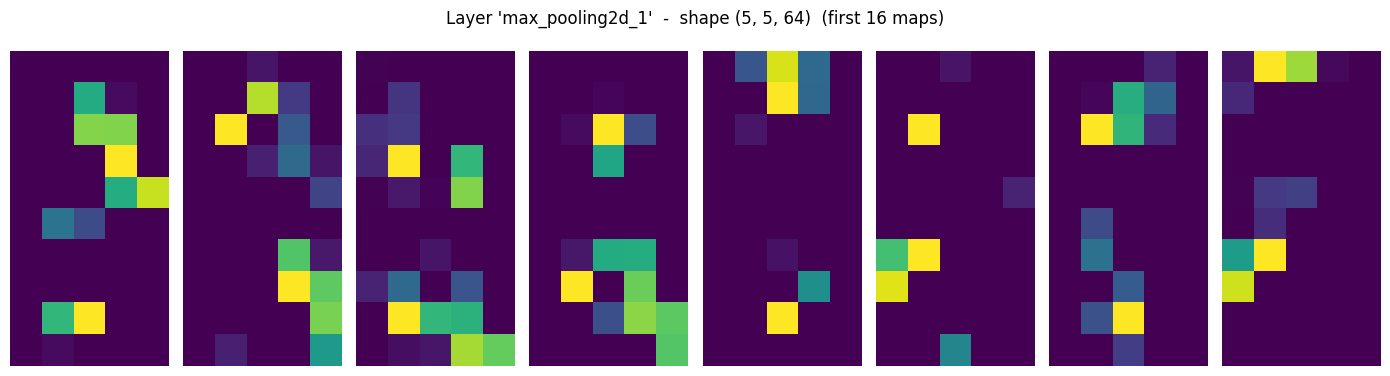

In [28]:
# Build a helper model that returns the outputs of the conv + pooling layers
layer_outputs = [l.output for l in cnn_improved.layers
                 if isinstance(l, (layers.Conv2D, layers.MaxPooling2D))]
layer_names   = [l.name for l in cnn_improved.layers
                 if isinstance(l, (layers.Conv2D, layers.MaxPooling2D))]

activation_model = keras.Model(inputs=cnn_improved.inputs, outputs=layer_outputs)

sample_idx = 7                                   # change this number to try other digits
sample_img = x_test[sample_idx:sample_idx+1]
activations = activation_model.predict(sample_img, verbose=0)

plt.figure(figsize=(3, 3))
plt.imshow(sample_img[0, :, :, 0], cmap='gray')
plt.title(f"Input image (label = {y_test[sample_idx]})")
plt.axis('off'); plt.show()

def show_feature_maps(act, name, n_cols=8, n_maps=16):
    n_maps = min(n_maps, act.shape[-1])
    n_rows = int(np.ceil(n_maps / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 1.9 * n_rows))
    axes = np.atleast_2d(axes)
    for k, ax in enumerate(axes.flat):
        if k < n_maps:
            ax.imshow(act[0, :, :, k], cmap='viridis')
        ax.axis('off')
    plt.suptitle(f"Layer '{name}'  -  shape {act.shape[1:]}  (first {n_maps} maps)", fontsize=12)
    plt.tight_layout(); plt.show()

for act, name in zip(activations, layer_names):
    show_feature_maps(act, name)

### 🔍 Observations for students
* **First layer:** maps highlight simple strokes and edges – the digit is still clearly recognisable.
* **After pooling:** maps are smaller, with the key features preserved.
* **Deeper layer:** maps are more abstract (parts of digits); they are harder for a human to interpret but more useful for classification.

This is called **hierarchical feature learning** – the main reason CNNs are so powerful.

---
# Part 10: Save, Load and Predict

We use the modern **`.keras`** format (the older `.h5` format is legacy).

In [29]:
cnn_improved.save('mnist_cnn_model.keras')
print("Model saved as mnist_cnn_model.keras")
print("File size: %.1f KB" % (os.path.getsize('mnist_cnn_model.keras') / 1024))

loaded_cnn = keras.models.load_model('mnist_cnn_model.keras')
print("Model loaded successfully!")

# Sanity check: the loaded model must give the same accuracy
_, acc_loaded = loaded_cnn.evaluate(x_test, y_test, verbose=0)
print(f"Loaded model test accuracy: {acc_loaded*100:.2f}%")

Model saved as mnist_cnn_model.keras
File size: 442.0 KB
Model loaded successfully!
Loaded model test accuracy: 99.24%


### Predict on 10 random test images

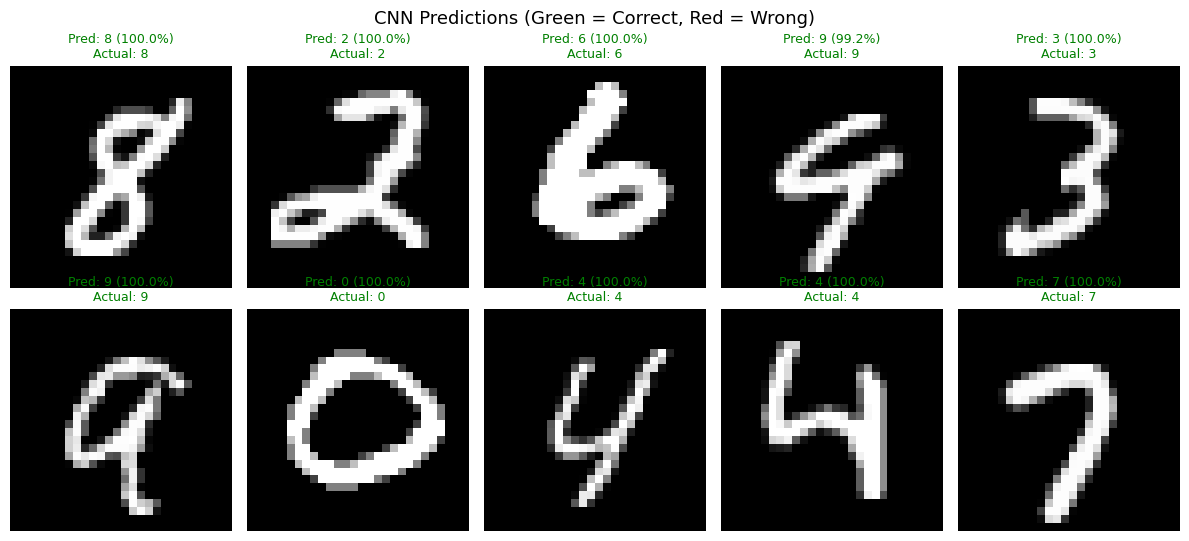

In [30]:
rng = np.random.default_rng(7)
random_indices = rng.choice(len(x_test), 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, idx in zip(axes.flat, random_indices):
    probs = loaded_cnn.predict(x_test[idx:idx+1], verbose=0)[0]
    pred  = np.argmax(probs)
    actual = y_test[idx]
    ax.imshow(x_test[idx, :, :, 0], cmap='gray')
    ax.set_title(f"Pred: {pred} ({probs[pred]*100:.1f}%)\nActual: {actual}",
                 color='green' if pred == actual else 'red', fontsize=9)
    ax.axis('off')
plt.suptitle("CNN Predictions (Green = Correct, Red = Wrong)", fontsize=13)
plt.tight_layout(); plt.show()

### Bar chart of probabilities for one image
Softmax outputs a **probability for every digit**. A confident model puts nearly all probability on one digit.

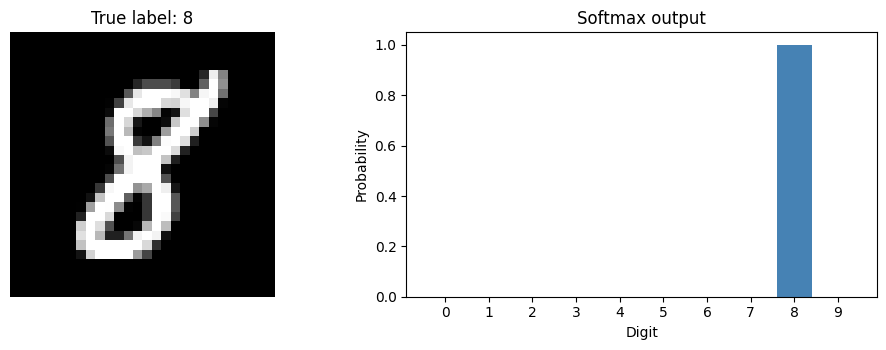

Sum of probabilities = 1.0


In [31]:
idx = random_indices[0]
probs = loaded_cnn.predict(x_test[idx:idx+1], verbose=0)[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].imshow(x_test[idx, :, :, 0], cmap='gray'); axes[0].axis('off')
axes[0].set_title(f"True label: {y_test[idx]}")
axes[1].bar(range(10), probs, color='steelblue')
axes[1].set_xticks(range(10)); axes[1].set_xlabel("Digit"); axes[1].set_ylabel("Probability")
axes[1].set_title("Softmax output")
plt.tight_layout(); plt.show()

print("Sum of probabilities =", probs.sum().round(4))

---
# Part 11: Predict Your Own Handwritten Digit ✍️

**Steps for students**
1. Write **one digit** (0–9) with a **thick dark pen on white paper** (or draw it in any paint app).
2. Take a photo or screenshot and keep only the digit area; save as PNG/JPG.
3. Run the cell below and upload the file.

### ⚠️ Why the image needs special treatment
MNIST digits are **white on black**, **centred**, and fit in a **20×20 box** inside 28×28.  
A normal photo is **black on white**. If we do not convert it, the network sees a *different kind of image* and predicts wrongly!

The function below therefore: ① converts to grayscale → ② **inverts** if the background is bright → ③ crops to the digit → ④ resizes keeping the aspect ratio → ⑤ centres it on a 28×28 canvas.

In [32]:
from PIL import Image, ImageOps

def preprocess_custom_image(path):
    # Convert any user image into MNIST-style 28x28 array
    img = Image.open(path).convert('L')            # 1. grayscale

    # 2. MNIST = white digit on black background. Invert if our background is bright.
    if np.array(img).mean() > 127:
        img = ImageOps.invert(img)

    arr = np.array(img)

    # 3. Remove faint background noise and crop to the digit's bounding box
    arr = np.where(arr < 40, 0, arr).astype('uint8')
    ys, xs = np.where(arr > 0)
    if len(xs) == 0:
        raise ValueError("No digit found in the image - is it blank?")
    arr = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]

    # 4. Resize so the longer side = 20 px (keep aspect ratio, like MNIST)
    h, w = arr.shape
    scale = 20.0 / max(h, w)
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    digit = Image.fromarray(arr).resize((new_w, new_h), Image.LANCZOS)

    # 5. Paste at the centre of a 28x28 black canvas
    canvas = Image.new('L', (28, 28), 0)
    canvas.paste(digit, ((28 - new_w) // 2, (28 - new_h) // 2))

    return np.array(canvas).astype('float32') / 255.0      # normalise

def predict_custom(path, model):
    arr = preprocess_custom_image(path)
    probs = model.predict(arr.reshape(1, 28, 28, 1), verbose=0)[0]
    pred = int(np.argmax(probs))

    original = Image.open(path)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    axes[0].imshow(original, cmap='gray'); axes[0].set_title("Your uploaded image")
    axes[1].imshow(arr, cmap='gray');      axes[1].set_title("What the CNN sees (28x28)")
    axes[2].bar(range(10), probs, color='steelblue')
    axes[2].set_xticks(range(10)); axes[2].set_title(f"Prediction: {pred}  ({probs[pred]*100:.1f}%)")
    for ax in axes[:2]: ax.axis('off')
    plt.tight_layout(); plt.show()
    print(f"Predicted digit: {pred}   |   Confidence: {probs[pred]*100:.1f}%")

Saving 3.png to 3.png
Saving 4.png to 4.png

File: 3.png


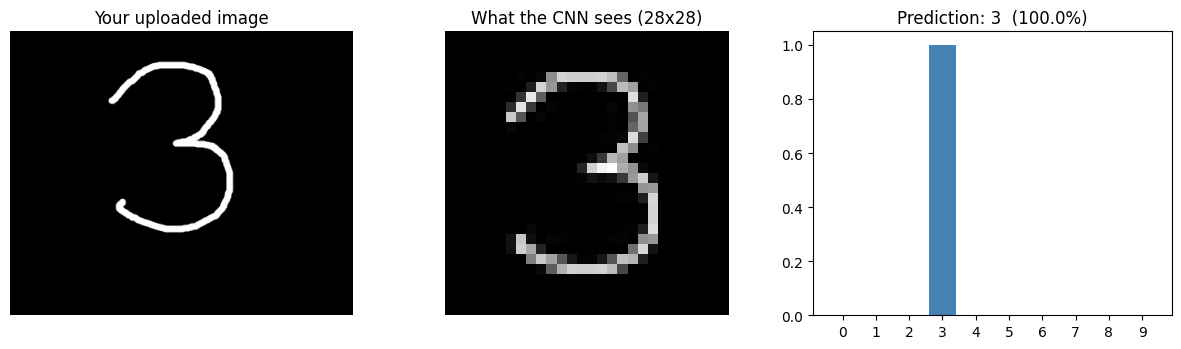

Predicted digit: 3   |   Confidence: 100.0%

File: 4.png


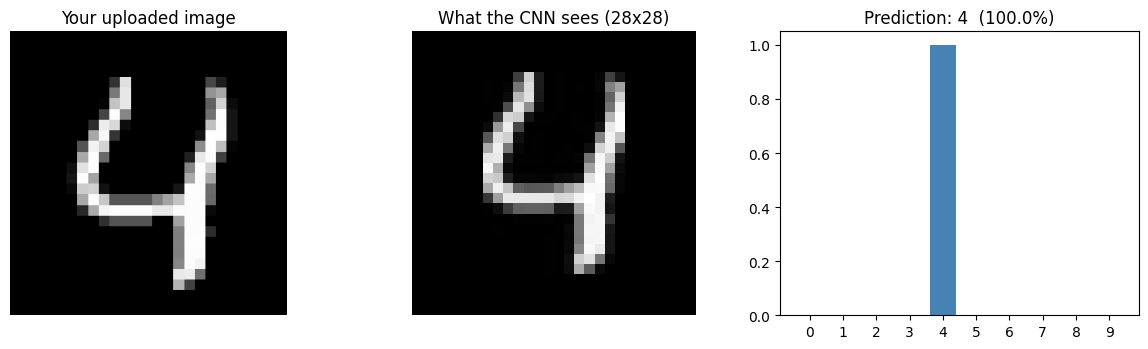

Predicted digit: 4   |   Confidence: 100.0%


In [33]:
# Upload one or more images (works in Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    for fname in uploaded.keys():
        print("\n" + "=" * 60)
        print("File:", fname)
        predict_custom(fname, loaded_cnn)
except ImportError:
    print("Not running in Colab. Call predict_custom('your_image.png', loaded_cnn) with a local path.")

### 💬 Discussion
* Compare the *"Your uploaded image"* with *"What the CNN sees"*. Do they look similar to MNIST digits?
* Try **without** the inversion/centring step – what happens to the prediction?
* Try a very thin pen, a very thick pen, a tilted digit. Where does the model fail? Why?  
  *(MNIST was written by about 500 writers; it has no tilted, thin or styled digits → **data distribution matters**.)*

---
# Part 12: Summary

| Step | What we did |
|------|-------------|
| 1 | Loaded MNIST and explored images, labels and class balance |
| 2 | Normalised pixels and reshaped images to `(28, 28, 1)` |
| 3 | Understood convolution, ReLU and pooling by implementing them manually |
| 4 | Built **Simple CNN** (1 conv layer) and computed its parameters by hand |
| 5 | Built **Improved CNN** (2 × Conv + Pool + Dropout) with EarlyStopping |
| 6 | Compared ANN vs CNN in accuracy and number of parameters |
| 7 | Analysed the confusion matrix, classification report and mistakes |
| 8 | Visualised learned filters and feature maps |
| 9 | Saved/loaded the model in `.keras` format |
| 10 | Predicted our own handwritten digits |

### 📌 Key Points to Remember

| Concept | One-line summary |
|---------|------------------|
| Convolution | Slides a small filter over the image to detect local patterns |
| Weight sharing | Same filter everywhere → very few parameters |
| Pooling | Down-samples feature maps, adds small shift-tolerance |
| Dropout | Randomly switches off neurons during training to reduce overfitting |
| EarlyStopping | Stops training when validation loss stops improving |
| Output size | $\lfloor (n + 2p - f)/s \rfloor + 1$ |
| Conv params | $(f_h \times f_w \times C_{in} + 1) \times \text{n\_filters}$ |

---

# 🏋️ Practice Exercises

**Level 1 – Easy**
1. Change the number of filters in `Simple_CNN` from 32 to 8 and then to 64. Record the parameters and accuracy.
2. Change `epochs` to 3 and then 20. What happens to the training/validation curves?
3. Change the kernel size from 3×3 to 5×5. Predict the new output shape and parameter count *before* running.

**Level 2 – Medium**
4. Use `padding='same'` in both conv layers. How do the output shapes change?
5. Replace `Adam` with `SGD(learning_rate=0.01, momentum=0.9)`. Which optimiser converges faster?
6. Change the Dropout rate to 0, 0.25, 0.5, 0.75 and plot test accuracy against the dropout rate.
7. Replace `MaxPooling2D` by `AveragePooling2D`. Compare results.

**Level 3 – Challenge**
8. Add a **third** conv block (64 → 128 filters). Does accuracy improve? Is the model overfitting?
9. Add **BatchNormalization** after each Conv layer.
10. Use **data augmentation** (`layers.RandomRotation(0.1)`, `layers.RandomZoom(0.1)`, `layers.RandomTranslation(0.1, 0.1)`) at the start of the model and test on your own tilted handwritten digits.
11. Apply the same CNN to **Fashion-MNIST** (`keras.datasets.fashion_mnist`). Which classes are hardest?

---

# ❓ Viva / Quiz Questions

1. Why do we flatten the image for an ANN but not for a CNN's convolution layers?
2. What is a *filter* and what is a *feature map*?
3. What is *weight sharing* and why does it reduce parameters?
4. Calculate the output shape for input 32×32×3, 5×5 filter, 16 filters, stride 1, no padding. *(28×28×16)*
5. How many parameters are in that layer? *(5×5×3+1)×16 = 1,216*
6. Why does a pooling layer have zero trainable parameters?
7. Why is the activation of the last layer Softmax and not ReLU?
8. What is the difference between *validation* data and *test* data?
9. The training accuracy is 99.9% but the validation accuracy is 97%. What is happening and how can you fix it?
10. Why must a photographed digit be inverted and centred before prediction?

---

> 🎉 **Great work!** You have built, analysed and deployed a Convolutional Neural Network from scratch. Next steps: *data augmentation, transfer learning (VGG / ResNet / MobileNet), and object detection*.

*Prepared for the NIELIT Deep Learning course – Anita Budhiraja.*